<a href="https://colab.research.google.com/github/SubhanArif-10/bookstore-web-scraper/blob/main/23i_5135_Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2: The Bookstore Intelligence Mission



## Mission 1 — Reconnaissance

### Reconnaissance Findings Table

| Data Needed | HTML Tag / Class Found | Your Notes |
| :--- | :--- | :--- |
| **Product Card (Container)** | `<article class="product_pod">` | Wraps each individual book on the page (20 books per page). |
| **Book Title** | `<h3>` -> `<a title="...">` | The visible link text is truncated with “...”, so the full title must be read from the title attribute rather than the text. |
| **Price** | `<p class="price_color">` | Stored as text with a currency symbol (e.g. £51.77). The £ must be removed and the value converted to a float before analysis. |
| **Rating** | `<p class="star-rating Three">` | Stored as a word (One to Five), not a number. A mapping dictionary converts it to 1-5. |
| **Availability** | `<p class="instock availability">` | Text is surrounded by extra whitespace (" In stock "), so it must be stripped. |
| **Product URL (Bonus 2)** | `<h3>` -> `<a href="...">` | Relative link to the product page; we join it with `https://books.toscrape.com/catalogue/`. |



## Mission 2 — Capture the Data

In [1]:
import requests
import pandas as pd
from bs4 import BeautifulSoup

# Convert rating words to numbers
ratings = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

# Download page 1
url = "https://books.toscrape.com/catalogue/page-1.html"
response = requests.get(url)
response.encoding = "utf-8"          # keeps the £ symbol clean
soup = BeautifulSoup(response.text, "html.parser")

# Collect the data
books = []
for card in soup.select("article.product_pod"):
    title = card.h3.a["title"]
    price = float(card.select_one("p.price_color").text.replace("£", ""))
    rating = ratings[card.select_one("p.star-rating")["class"][1]]
    availability = card.select_one("p.availability").text.strip()
    link = "https://books.toscrape.com/catalogue/" + card.h3.a["href"]

    books.append({
        "Title": title,
        "Price": price,
        "Rating": rating,
        "Availability": availability,
        "URL": link
    })

# Put it in a DataFrame
df = pd.DataFrame(books)
print(df.shape)
df.head()

(20, 5)


,Title,Price,Rating,Availability,URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


##Mission 3 — Scale the Operation

In [6]:
import time

ratings = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

def scrape_page(page_number):
    url = f"https://books.toscrape.com/catalogue/page-{page_number}.html"
    response = requests.get(url)
    if response.status_code != 200:
        return None                      # page doesn't exist or failed
    response.encoding = "utf-8"
    soup = BeautifulSoup(response.text, "html.parser")

    books = []
    for card in soup.select("article.product_pod"):
        books.append({
            "Title": card.h3.a["title"],
            "Price": float(card.select_one("p.price_color").text.replace("£", "")),
            "Rating": ratings[card.select_one("p.star-rating")["class"][1]],
            "Availability": card.select_one("p.availability").text.strip(),
            "URL": "https://books.toscrape.com/catalogue/" + card.h3.a["href"]
        })
    return books

# Loop over the pages
NUM_PAGES = 50     # Bonus 1 and Boss Level

all_books = []
for page in range(1, NUM_PAGES + 1):
    page_books = scrape_page(page)
    if page_books is None:
        print(f"Page {page} failed, stopping.")
        break
    all_books.extend(page_books)
    print(f"Page {page} done: {len(all_books)} books so far")
    time.sleep(0.3)    # be polite to the server

df = pd.DataFrame(all_books)

# Check the DataFrame
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
df.head(10)

Page 1 done: 20 books so far
Page 2 done: 40 books so far
Page 3 done: 60 books so far
Page 4 done: 80 books so far
Page 5 done: 100 books so far
Page 6 done: 120 books so far
Page 7 done: 140 books so far
Page 8 done: 160 books so far
Page 9 done: 180 books so far
Page 10 done: 200 books so far
Page 11 done: 220 books so far
Page 12 done: 240 books so far
Page 13 done: 260 books so far
Page 14 done: 280 books so far
Page 15 done: 300 books so far
Page 16 done: 320 books so far
Page 17 done: 340 books so far
Page 18 done: 360 books so far
Page 19 done: 380 books so far
Page 20 done: 400 books so far
Page 21 done: 420 books so far
Page 22 done: 440 books so far
Page 23 done: 460 books so far
Page 24 done: 480 books so far
Page 25 done: 500 books so far
Page 26 done: 520 books so far
Page 27 done: 540 books so far
Page 28 done: 560 books so far
Page 29 done: 580 books so far
Page 30 done: 600 books so far
Page 31 done: 620 books so far
Page 32 done: 640 books so far
Page 33 done: 660 boo

,Title,Price,Rating,Availability,URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...
5,The Requiem Red,22.65,1,In stock,https://books.toscrape.com/catalogue/the-requi...
6,The Dirty Little Secrets of Getting Your Dream...,33.34,4,In stock,https://books.toscrape.com/catalogue/the-dirty...
7,The Coming Woman: A Novel Based on the Life of...,17.93,3,In stock,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,22.60,4,In stock,https://books.toscrape.com/catalogue/the-boys-...
9,The Black Maria,52.15,1,In stock,https://books.toscrape.com/catalogue/the-black...


In [7]:
df.to_csv("competitor_books.csv", index=False)

from google.colab import files
files.download("competitor_books.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Mission 4 — Intelligence Analysis

In [8]:
# 1. Most expensive
exp = df.loc[df["Price"].idxmax()]
print("1. Most expensive:", exp["Title"], f"(£{exp['Price']})")

# 2. Cheapest
chp = df.loc[df["Price"].idxmin()]
print("2. Cheapest:", chp["Title"], f"(£{chp['Price']})")

# 3. Average price
print("3. Average price: £%.2f" % df["Price"].mean())

# 4. Number of 5-star books
print("4. Five-star books:", (df["Rating"] == 5).sum())

# 5. Percentage in stock
in_stock = df["Availability"].str.contains("In stock").mean() * 100
print("5. In stock: %.1f%%" % in_stock)

# 6. Top 5 highest-rated (ties broken by lowest price)
print("\n6. Top 5 highest-rated books:")
top5 = df.sort_values(["Rating", "Price"], ascending=[False, True]).head(5)
print(top5[["Title", "Price", "Rating"]].to_string(index=False))

# 7. Cheapest among the 5-star books
five = df[df["Rating"] == 5]
cheap5 = five.loc[five["Price"].idxmin()]
print("\n7. Cheapest 5-star book:", cheap5["Title"], f"(£{cheap5['Price']})")

1. Most expensive: The Perfect Play (Play by Play #1) (£59.99)
2. Cheapest: An Abundance of Katherines (£10.0)
3. Average price: £35.07
4. Five-star books: 196
5. In stock: 100.0%

6. Top 5 highest-rated books:
                                                     Title  Price  Rating
                                An Abundance of Katherines  10.00       5
                                      Greek Mythic History  10.23       5
The Power Greens Cookbook: 140 Delicious Superfood Recipes  11.05       5
                                        Dear Mr. Knightley  11.21       5
                                       The Darkest Corners  11.33       5

7. Cheapest 5-star book: An Abundance of Katherines (£10.0)


In [9]:
print(df[df["Price"] == df["Price"].min()][["Title", "Price"]])
print(df[df["Price"] == df["Price"].max()][["Title", "Price"]])
print(five[five["Price"] == five["Price"].min()][["Title", "Price", "Rating"]])

                          Title  Price
638  An Abundance of Katherines   10.0
                                  Title  Price
648  The Perfect Play (Play by Play #1)  59.99
                          Title  Price  Rating
638  An Abundance of Katherines   10.0       5


**Dataset:** all 50 catalogue pages scraped from books.toscrape.com (1,000 books).

| # | Question | Answer |
|---|----------|--------|
| 1 | Most expensive book | *The Perfect Play (Play by Play #1)*, £59.99 |
| 2 | Cheapest book | *An Abundance of Katherines*, £10.00 |
| 3 | Average book price | £35.07 |
| 4 | Number of 5-star books | 196 |
| 5 | Percentage of books in stock | 100% |
| 6 | Top 5 highest-rated books | See table below |
| 7 | Cheapest 5-star book | *An Abundance of Katherines*, £10.00 |

### Q6: Top 5 highest-rated books

196 books share the 5-star rating, so I ranked by rating and broke ties by lowest price.

| Rank | Title | Price | Rating |
|------|-------|-------|--------|
| 1 | An Abundance of Katherines | £10.00 | 5 |
| 2 | Greek Mythic History | £10.23 | 5 |
| 3 | The Power Greens Cookbook: 140 Delicious Superfood Recipes | £11.05 | 5 |
| 4 | Dear Mr. Knightley | £11.21 | 5 |
| 5 | The Darkest Corners | £11.33 | 5 |

### Notes
- **Q5:** All 1,000 books show "In stock". This is a property of the sandbox website, not an error in the scraper.
- **Q1, Q2, Q7:** I checked for price ties, and each answer is a single book.

## Business Decision

In [10]:
avg_all = df["Price"].mean()
avg_5 = df[df["Rating"] == 5]["Price"].mean()
pct_4plus = (df["Rating"] >= 4).mean() * 100
cheap_good = ((df["Rating"] >= 4) & (df["Price"] < avg_all)).sum()
corr = df["Price"].corr(df["Rating"])

print("Average price (all books): £%.2f" % avg_all)
print("Average price (5-star books): £%.2f" % avg_5)
print("Share of books rated 4+ stars: %.1f%%" % pct_4plus)
print("Books rated 4+ AND priced below average:", cheap_good)
print("Correlation between price and rating: %.3f" % corr)

Average price (all books): £35.07
Average price (5-star books): £35.37
Share of books rated 4+ stars: 37.5%
Books rated 4+ AND priced below average: 171
Correlation between price and rating: 0.028


**Manager's question:** Which books would I prioritise if launching a competing online bookstore?

**Recommendation:** I would prioritise books rated 4 or 5 stars and priced below the catalogue average of £35.07, because this gives us well-reviewed titles at competitive prices. Price and rating are almost uncorrelated (r = 0.028), and 5-star books average £35.37 compared with £35.07 for all books, so customer-approved titles cost no more to stock. Also, 37.5% of the 1,000 scraped books are rated 4+ stars and 171 of them are priced below average, which gives us a large pool of affordable, highly rated books to launch with.

| Evidence | Value |
|----------|-------|
| Average price (all books) | £35.07 |
| Average price (5-star books) | £35.37 |
| Price vs rating correlation | 0.028 |
| Share of books rated 4+ stars | 37.5% |
| Books rated 4+ AND below average price | 171 |

## Final Challenge — The CEO Has £100

In [11]:
import numpy as np

budget = 10000                                   # £100 in pence
prices = (df["Price"] * 100).round().astype(int).tolist()
stars = df["Rating"].tolist()
n = len(df)

# value = stars first, lower cost as the tie-breaker
values = [s * 1_000_000 - p for s, p in zip(stars, prices)]

dp = np.zeros(budget + 1, dtype=np.int64)
take = np.zeros((n, budget + 1), dtype=bool)

for i in range(n):
    p, v = prices[i], values[i]
    if p > budget:
        continue
    cand = dp[:budget + 1 - p] + v
    better = cand > dp[p:]
    take[i, p:] = better
    dp[p:] = np.where(better, cand, dp[p:])

# Trace back which books were chosen
w, chosen = budget, []
for i in range(n - 1, -1, -1):
    if take[i, w]:
        chosen.append(i)
        w -= prices[i]

pick = df.iloc[chosen][["Title", "Price", "Rating"]].sort_values("Price")
print(pick.to_string(index=False))
print(f"\nBooks: {len(pick)} | Total cost: £{pick['Price'].sum():.2f} | Total stars: {pick['Rating'].sum()}")

                                                                                  Title  Price  Rating
                                                             An Abundance of Katherines  10.00       5
                                                                  The Origin of Species  10.01       4
                                                                   Greek Mythic History  10.23       5
                             The Power Greens Cookbook: 140 Delicious Superfood Recipes  11.05       5
                                                                     Dear Mr. Knightley  11.21       5
                                                                    The Darkest Corners  11.33       5
Naturally Lean: 125 Nourishing Gluten-Free, Plant-Based Recipes--All Under 300 Calories  11.38       5
                                               Fruits Basket, Vol. 2 (Fruits Basket #2)  11.64       5
                                                  Old School (Diary of a 

**Goal:** choose books from the scraped dataset that maximise total star rating without spending more than £100.

| # | Title | Price | Rating |
|---|-------|-------|--------|
| 1 | An Abundance of Katherines | £10.00 | 5 |
| 2 | The Origin of Species | £10.01 | 4 |
| 3 | Greek Mythic History | £10.23 | 5 |
| 4 | The Power Greens Cookbook: 140 Delicious Superfood Recipes | £11.05 | 5 |
| 5 | Dear Mr. Knightley | £11.21 | 5 |
| 6 | The Darkest Corners | £11.33 | 5 |
| 7 | Naturally Lean: 125 Nourishing Gluten-Free, Plant-Based Recipes--All Under 300 Calories | £11.38 | 5 |
| 8 | Fruits Basket, Vol. 2 (Fruits Basket #2) | £11.64 | 5 |
| 9 | Old School (Diary of a Wimpy Kid #10) | £11.83 | 5 |

**Total cost:** £98.68  
**Total rating score:** 44 stars (9 books)

**Justification:** I used an optimisation (knapsack) approach rather than picking by hand, so this is the maximum possible star total within £100 for my scraped dataset of 1,000 books. Eight of the nine books are 5-star titles priced around £10-£12, and one 4-star book was included because it was the best way to use the remaining budget.

### Bonus 3 and Bonus 4

Rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64


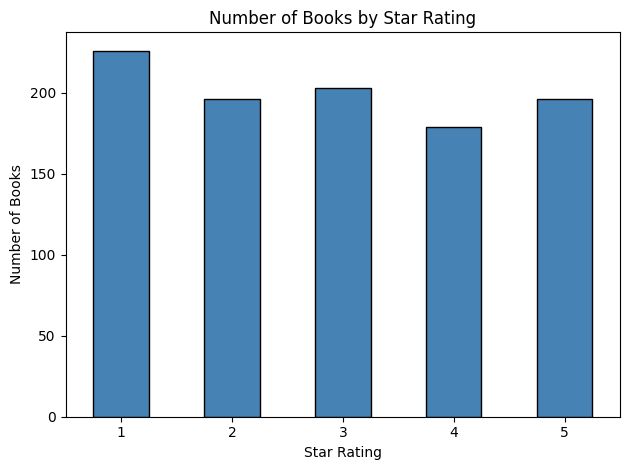

In [12]:
import matplotlib.pyplot as plt

rating_counts = df["Rating"].value_counts().sort_index()
print(rating_counts)

rating_counts.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Number of Books by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("rating_counts.png", dpi=150)
plt.show()

In [13]:
from google.colab import files
files.download("rating_counts.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Bonus Missions

**Bonus 1:** Scraped 5 pages (and then all 50 pages, 1,000 books, using the same loop).

**Bonus 2:** Product page URL added as the `URL` column.

**Bonus 3: Number of books per star rating**

| Star Rating | Number of Books |
|-------------|-----------------|
| 1 | 226 |
| 2 | 196 |
| 3 | 203 |
| 4 | 179 |
| 5 | 196 |

**Bonus 4:** Bar chart of rating counts (above). The distribution is fairly even across all five rating levels, with 1-star books the most common (226) and 4-star the least common (179).

**Boss Level:** The same reusable `scrape_page()` function and loop was used to scrape all 50 catalogue pages (1,000 books).